In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sb
import warnings
import sqlite3
from scipy.stats import ttest_ind
import scipy.stats as stats
warnings.filterwarnings('ignore')
import urllib
from sqlalchemy import create_engine

In [2]:
server = 'RDsDevice\SQLEXPRESS01'
database = 'Inventory'

connection_string = (
    "DRIVER={ODBC Driver 17 for SQL Server};"
    f"SERVER={server};"
    f"DATABASE={database};"
    "Trusted_Connection=yes;"
)

params = urllib.parse.quote_plus(connection_string)

engine = create_engine(
    f"mssql+pyodbc:///?odbc_connect={params}"
)

In [3]:
query = "SELECT * FROM Clean_Vendor____Sales____Summary"

df = pd.read_sql(query, engine)

In [4]:
df

,VendorNo,Brand,Description,FreightCost,vendorname,purchaseprice,TotalPurchaseQuantity,TotalPurchaseDollar,volume,SellingPrice,TotalSalesDollars,TotalSalesPrice,TotalSalesQuantity,TotalExciseTax,GrossProfit,ProfitMargin,StockTurnover,SalestoPurchaseRatio
0,2,90085,Ch Lilian 09 Ladouys St Este,27.080001,"IRA GOLDMAN AND WILLIAMS, LLP",23.860001,8,190.880005,750.0,36.990002,665.820019,295.920013,18.0,2.000000,474.940014,71.331591,2.250000,3.488160
1,2,90609,Flavor Essence Variety 5 Pak,27.080001,"IRA GOLDMAN AND WILLIAMS, LLP",17.000000,320,5440.000000,162.5,24.990000,599.759998,449.819996,24.0,0.520000,-4840.240002,-807.029481,0.075000,0.110250
2,54,990,Ethyl Alcohol 200 Proof,0.480000,AAPER ALCOHOL & CHEMICAL CO,105.070000,1,105.070000,3750.0,134.490005,0.000000,0.000000,0.0,0.000000,-105.070000,NaN,0.000000,0.000000
3,60,771,Bak's Krupnik Honey Liqueur,367.520002,ADAMBA IMPORTS INTL INC,11.440000,39,446.159996,750.0,14.990000,704.529989,494.669992,47.0,37.010001,258.369993,36.672675,1.205128,1.579097
4,60,3401,Vesica Vodka,367.520002,ADAMBA IMPORTS INTL INC,11.100000,6,66.599998,1750.0,14.990000,0.000000,0.000000,0.0,0.000000,-66.599998,NaN,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10687,173357,2804,Camp Robber Whiskey,202.500001,TAMWORTH DISTILLING,32.139999,210,6749.399887,750.0,44.990002,6298.600163,3194.290119,140.0,110.330001,-450.799725,-7.157141,0.666667,0.933209
10688,173357,3666,Art in the Age Chicory Root,202.500001,TAMWORTH DISTILLING,18.790001,520,9770.799988,375.0,24.990000,8996.399963,4873.049955,360.0,141.189998,-774.400024,-8.607888,0.692308,0.920743
10689,173357,3848,Chicory Root Vodka,202.500001,TAMWORTH DISTILLING,23.299999,28,652.400009,750.0,30.990000,185.939999,92.969999,6.0,4.710000,-466.460011,-250.865878,0.214286,0.285009
10690,173357,3909,White Mountain Vodka,202.500001,TAMWORTH DISTILLING,19.370001,1232,23863.840233,750.0,24.990000,24540.179880,14469.209867,982.0,773.870011,676.339647,2.756050,0.797078,1.028342


In [5]:
pd.set_option('display.float_format','{:2f}'.format)


In [6]:
df

,VendorNo,Brand,Description,FreightCost,vendorname,purchaseprice,TotalPurchaseQuantity,TotalPurchaseDollar,volume,SellingPrice,TotalSalesDollars,TotalSalesPrice,TotalSalesQuantity,TotalExciseTax,GrossProfit,ProfitMargin,StockTurnover,SalestoPurchaseRatio
0,2,90085,Ch Lilian 09 Ladouys St Este,27.080001,"IRA GOLDMAN AND WILLIAMS, LLP",23.860001,8,190.880005,750.000000,36.990002,665.820019,295.920013,18.000000,2.000000,474.940014,71.331591,2.250000,3.488160
1,2,90609,Flavor Essence Variety 5 Pak,27.080001,"IRA GOLDMAN AND WILLIAMS, LLP",17.000000,320,5440.000000,162.500000,24.990000,599.759998,449.819996,24.000000,0.520000,-4840.240002,-807.029481,0.075000,0.110250
2,54,990,Ethyl Alcohol 200 Proof,0.480000,AAPER ALCOHOL & CHEMICAL CO,105.070000,1,105.070000,3750.000000,134.490005,0.000000,0.000000,0.000000,0.000000,-105.070000,NaN,0.000000,0.000000
3,60,771,Bak's Krupnik Honey Liqueur,367.520002,ADAMBA IMPORTS INTL INC,11.440000,39,446.159996,750.000000,14.990000,704.529989,494.669992,47.000000,37.010001,258.369993,36.672675,1.205128,1.579097
4,60,3401,Vesica Vodka,367.520002,ADAMBA IMPORTS INTL INC,11.100000,6,66.599998,1750.000000,14.990000,0.000000,0.000000,0.000000,0.000000,-66.599998,NaN,0.000000,0.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10687,173357,2804,Camp Robber Whiskey,202.500001,TAMWORTH DISTILLING,32.139999,210,6749.399887,750.000000,44.990002,6298.600163,3194.290119,140.000000,110.330001,-450.799725,-7.157141,0.666667,0.933209
10688,173357,3666,Art in the Age Chicory Root,202.500001,TAMWORTH DISTILLING,18.790001,520,9770.799988,375.000000,24.990000,8996.399963,4873.049955,360.000000,141.189998,-774.400024,-8.607888,0.692308,0.920743
10689,173357,3848,Chicory Root Vodka,202.500001,TAMWORTH DISTILLING,23.299999,28,652.400009,750.000000,30.990000,185.939999,92.969999,6.000000,4.710000,-466.460011,-250.865878,0.214286,0.285009
10690,173357,3909,White Mountain Vodka,202.500001,TAMWORTH DISTILLING,19.370001,1232,23863.840233,750.000000,24.990000,24540.179880,14469.209867,982.000000,773.870011,676.339647,2.756050,0.797078,1.028342


# Exploratory Analysis

##### Previously, we examined the various tables in the database to identify key variables, understand their relationships, and determine which ones should be included in the final analysis.

##### In this phase of EDA, we will analyze the resultant table to gain insights into the distribution of each column. This will help us understand data patterns, identify anomalies, and ensure data quality before proceeding with further analysis.


In [7]:
# Summary statistics

df.describe().T

,count,mean,std,min,25%,50%,75%,max
VendorNo,10692.000000,10650.649458,18753.519148,2.000000,3951.000000,7153.000000,9552.000000,201359.000000
Brand,10692.000000,18039.228769,12662.187074,58.000000,5793.500000,18761.500000,25514.250000,90631.000000
FreightCost,10692.000000,61433.763216,60938.458015,0.090000,14069.870026,50293.619843,79528.990326,257032.069523
purchaseprice,10692.000000,24.385303,109.269376,0.360000,6.840000,10.455000,19.482500,5681.810059
TotalPurchaseQuantity,10692.000000,3140.886831,11095.086769,1.000000,36.000000,262.000000,1975.750000,337660.000000
TotalPurchaseDollar,10692.000000,30106.693354,123067.799573,0.710000,453.457510,3655.464971,20738.244730,3811251.598572
volume,10692.000000,847.360550,664.309212,50.000000,750.000000,750.000000,750.000000,20000.000000
SellingPrice,10692.000000,35.643671,148.246018,0.490000,10.990000,15.990000,28.990000,7499.990234
TotalSalesDollars,10692.000000,42239.074317,167655.266047,0.000000,729.219982,5298.044970,28396.914894,5101919.546913
TotalSalesPrice,10692.000000,18793.783517,44952.773491,0.000000,289.709993,2857.799950,16059.562242,672819.341167


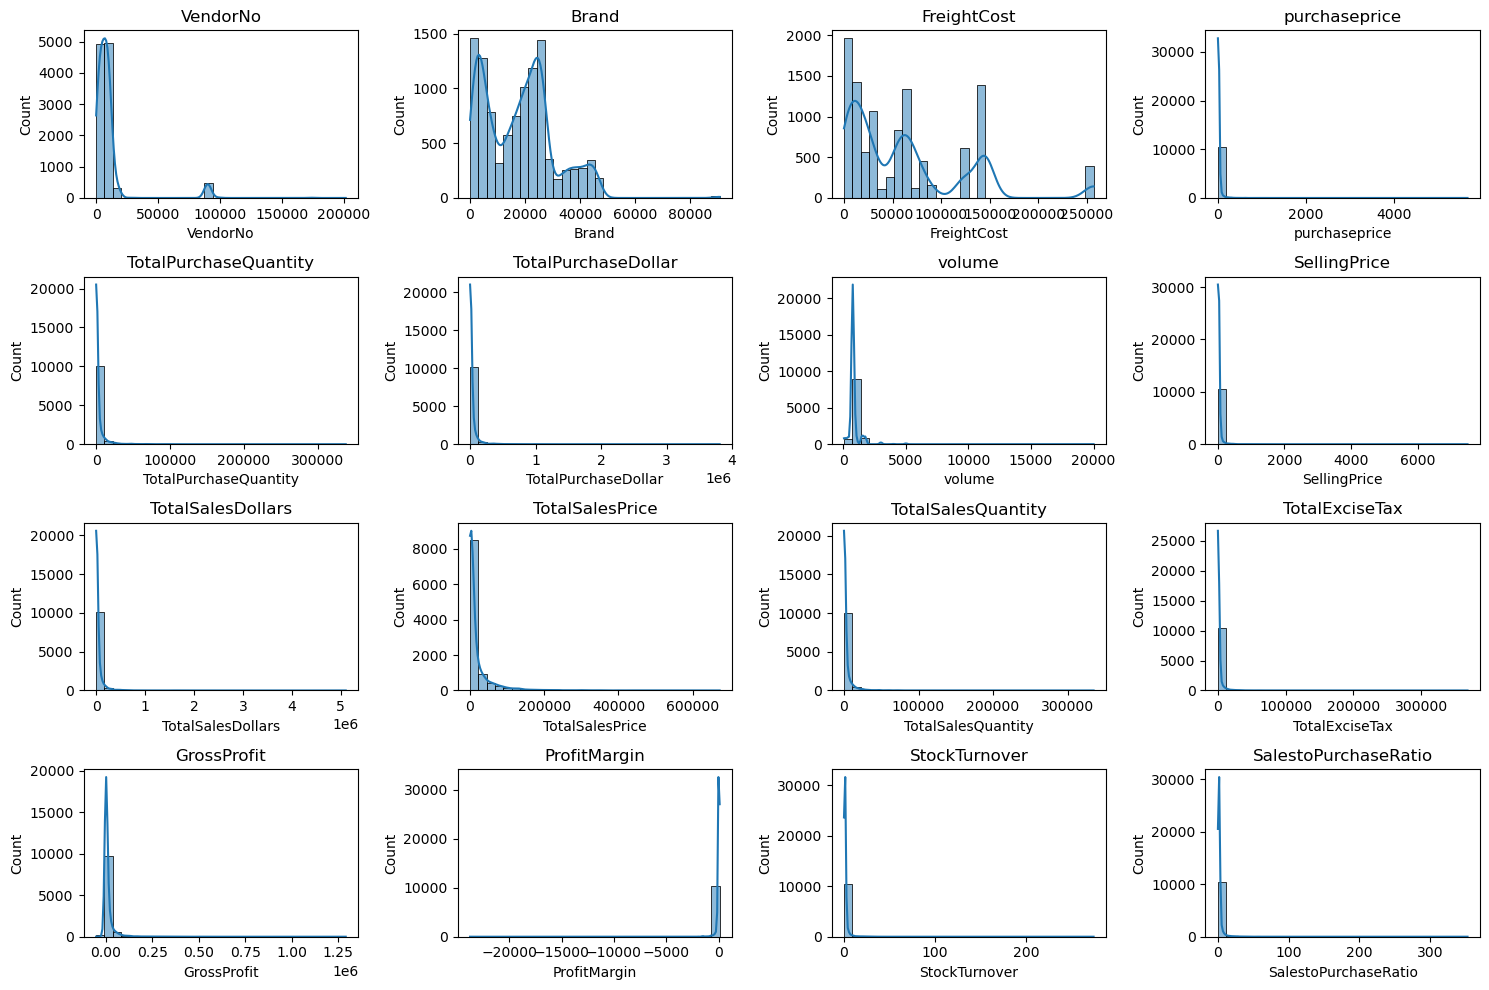

In [8]:
# Plot histogram to know the range of numeric columns

numerical_cols = df.select_dtypes(include = np.number).columns

plt.figure (figsize = (15,10))
for i,col in enumerate (numerical_cols):
    plt.subplot (4,4,i+1)  #Adjusted grid layout
    sb.histplot (df[col], kde =True, bins =30)
    plt.title(col)
plt.tight_layout()
plt.show()


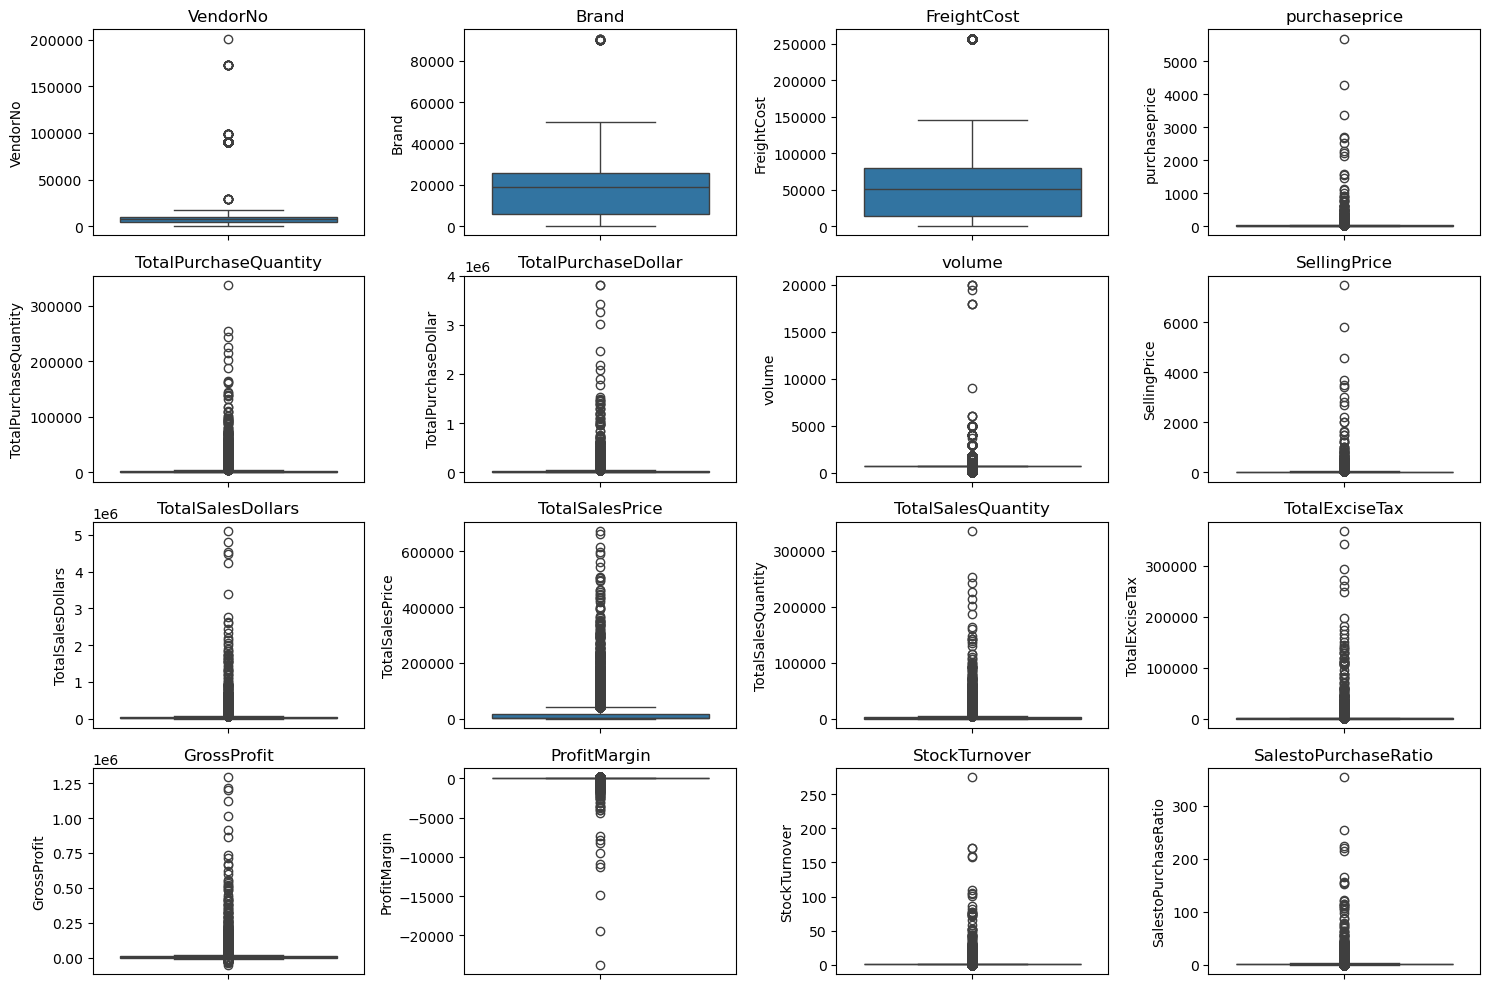

In [9]:
# Outlier detection with Boxplots

numerical_cols = df.select_dtypes(include = np.number).columns

plt.figure (figsize = (15,10))
for i,col in enumerate (numerical_cols):
    plt.subplot (4,4,i+1)  #Adjusted grid layout
    sb.boxplot (y=df[col],)
    plt.title(col)
plt.tight_layout()
plt.show()


# Summary Statistics Insights
### Negative & Zero Values:
##### Gross Profit: Minimum value is -52,002.78, indicating losses. Some products or transactions may be selling at a loss due to high costs or selling at discounts lower than the purchase price.
##### Profit Margin: Has a minimum of -∞, which suggests cases where revenue is zero or even lower than costs.
##### Total Sales Quantity & Sales Dollars: Minimum values are 0, meaning some products were purchased but never sold. These could be slow-moving or obsolete stock.
### Outliers Indicated by High Standard Deviations:
##### Purchase & Actual Prices: The max values (5,681.81 & 7,499.99) are significantly higher than the mean (24.39 & 35.64), indicating potential premium products.
##### Freight Cost: Huge variation, from 0.09 to 257,032.07, suggests logistics inefficiencies or bulk shipments.
##### Stock Turnover: Ranges from 0 to 274.5, implying some products sell extremely fast while others remain in stock indefinitely. Value more than 1 indicates that sold quantity for that product is higher than purchased quantity due to either sales being fulfilled from older stock.


In [10]:
# Filter data by removing inconsistencies

df = pd.read_sql_query(""" select * from Clean_Vendor____Sales____Summary
where grossprofit >0
and profitmargin >0
and totalsalesquantity >0""",engine)

In [11]:
df

,VendorNo,Brand,Description,FreightCost,vendorname,purchaseprice,TotalPurchaseQuantity,TotalPurchaseDollar,volume,SellingPrice,TotalSalesDollars,TotalSalesPrice,TotalSalesQuantity,TotalExciseTax,GrossProfit,ProfitMargin,StockTurnover,SalestoPurchaseRatio
0,2,90085,Ch Lilian 09 Ladouys St Este,27.080001,"IRA GOLDMAN AND WILLIAMS, LLP",23.860001,8,190.880005,750.000000,36.990002,665.820019,295.920013,18.000000,2.000000,474.940014,71.331591,2.250000,3.488160
1,60,771,Bak's Krupnik Honey Liqueur,367.520002,ADAMBA IMPORTS INTL INC,11.440000,39,446.159996,750.000000,14.990000,704.529989,494.669992,47.000000,37.010001,258.369993,36.672675,1.205128,1.579097
2,105,2529,Right Gin,62.389999,ALTAMAR BRANDS LLC,23.250000,12,279.000000,750.000000,29.990000,359.880005,59.980000,12.000000,9.440000,80.880005,22.474159,1.000000,1.289892
3,105,8412,Tequila Ocho Plata Fresno,62.389999,ALTAMAR BRANDS LLC,35.709999,320,11427.199730,750.000000,49.990002,15346.930485,12947.410435,307.000000,242.150006,3919.730755,25.540813,0.959375,1.343018
4,200,20789,Zin-phomaniac Znfdl,6.190000,AMERICAN SPIRITS EXCHANGE,9.730000,96,934.080017,750.000000,14.990000,1511.160019,287.839996,84.000000,9.430000,577.080002,38.187882,0.875000,1.617806
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8560,172662,2191,Clark & Chesterfield Whiskey,178.340000,SWEETWATER FARM,14.700000,138,2028.599963,375.000000,19.990000,2498.749987,1819.089979,125.000000,48.999999,470.150023,18.815409,0.905797,1.231761
8561,172662,2265,Monadnock Moonshine,178.340000,SWEETWATER FARM,21.469999,267,5732.490227,750.000000,28.990000,6435.779959,5363.149958,222.000000,175.130004,703.289732,10.927809,0.831461,1.122685
8562,172662,3632,Ashuelot Vodka,178.340000,SWEETWATER FARM,21.580000,554,11955.319658,750.000000,28.490000,12877.479950,8205.119934,452.000000,356.140004,922.160292,7.161031,0.815884,1.077134
8563,173357,3909,White Mountain Vodka,202.500001,TAMWORTH DISTILLING,19.370001,1232,23863.840233,750.000000,24.990000,24540.179880,14469.209867,982.000000,773.870011,676.339647,2.756050,0.797078,1.028342


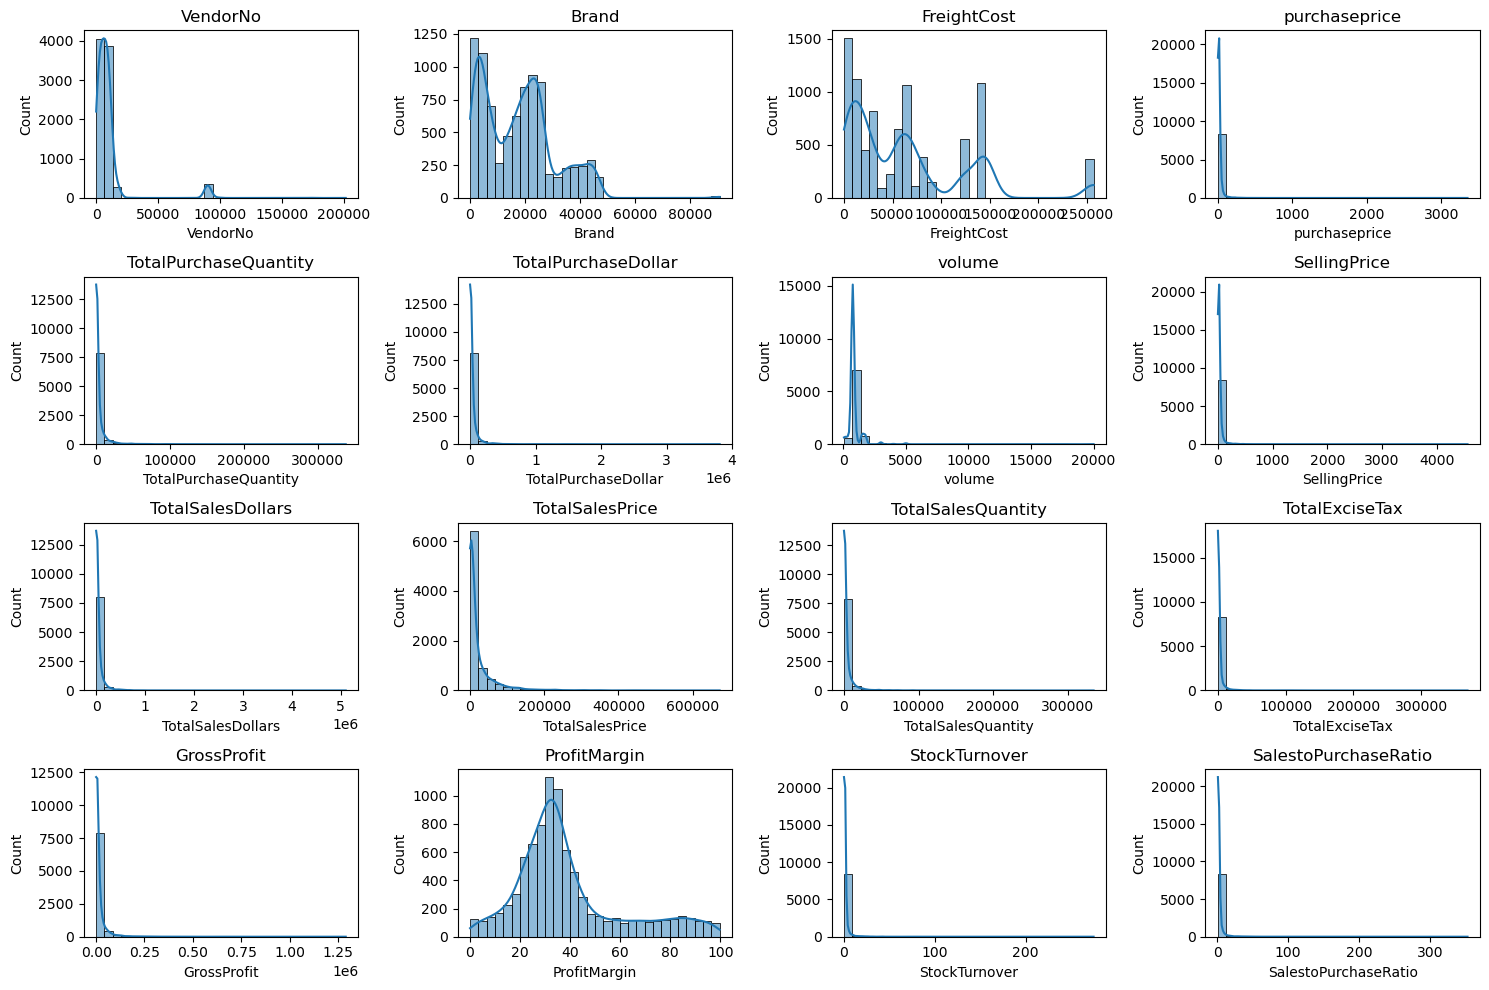

In [12]:
# Plot histogram to know the range of numeric columns

numerical_cols = df.select_dtypes(include = np.number).columns

plt.figure (figsize = (15,10))
for i,col in enumerate (numerical_cols):
    plt.subplot (4,4,i+1)  #Adjusted grid layout
    sb.histplot (df[col], kde =True, bins =30)
    plt.title(col)
plt.tight_layout()
plt.show()


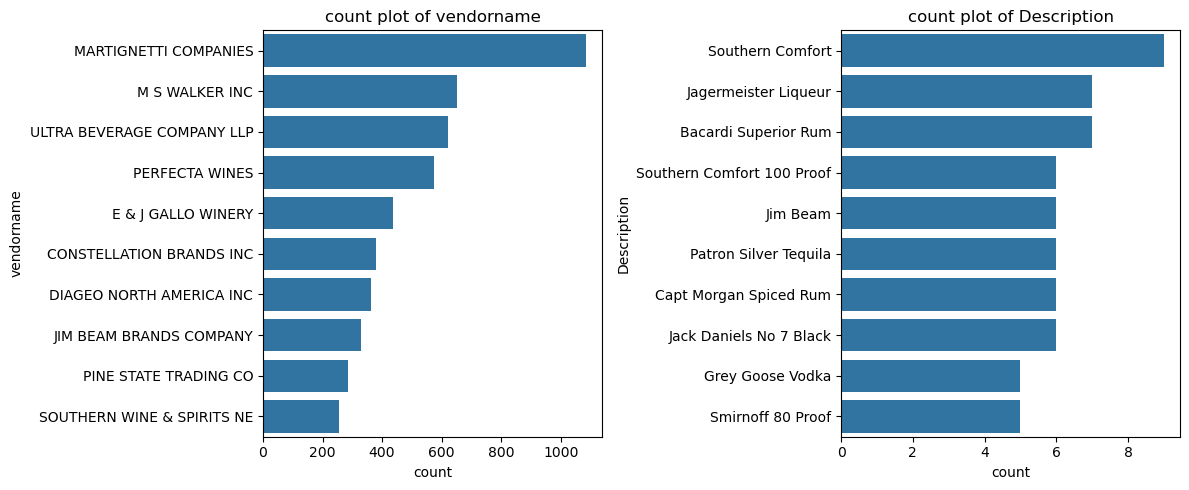

In [13]:
# Count plots for Categorical Columns

categorical_cols = ["vendorname","Description"]

plt.figure(figsize = (12,5))
for i,col in enumerate (categorical_cols):
    plt.subplot(1,2,i+1)
    sb.countplot(y=df[col],order = df[col].value_counts().index[:10]) # Top 10 categories
    plt.title(f"count plot of {col}")
plt.tight_layout()
plt.show()


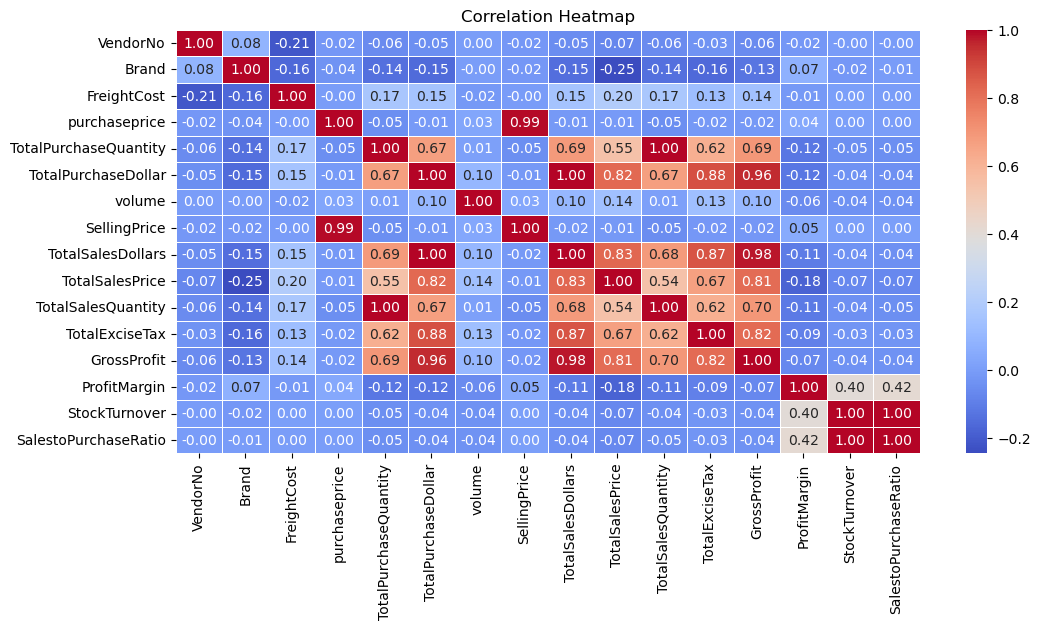

In [14]:
# Correlation Heatmap 

plt.figure(figsize = (12,5.5))
correlation_matrix = df[numerical_cols].corr()
sb.heatmap(correlation_matrix,annot = True,fmt = ".2f", cmap= "coolwarm",linewidths=0.5)
plt.title("Correlation Heatmap")
plt.show()

# Correlation Insights
#### PurchasePrice has weak correlations with TotalSalesDollars (-0.012) and GrossProfit (-0.016), suggesting that price variations do not significantly impact sales revenue or profit.
#### Strong correlation between total purchase quantity and total sales quantity (0.999), confirming efficient inventory turnover.
#### Negative correlation between profit margin & total sales price (-0.179) suggests that as sales price increases, margins decrease, possibly due to competitive pricing pressures.
#### StockTurnover has weak negative correlations with both GrossProfit (-0.038) and ProfitMargin (-0.055), indicating that faster turnover does not necessarily result in higher profitability.

In [15]:
#1. Identify underperforming brands that require promotional or pricing adjustments.

brand_performance = df.groupby('Description').agg({
    'TotalSalesDollars':'sum',
    'ProfitMargin':'mean'}).reset_index()


In [16]:
low_sales_threshold = brand_performance['TotalSalesDollars'].quantile(0.15)
high_margin_threshold = brand_performance['ProfitMargin'].quantile(0.85)


In [17]:
low_sales_threshold

np.float64(560.2989873886107)

In [18]:
high_margin_threshold

np.float64(64.9701755382603)

In [19]:
# Filter brands with low sales but high profit margins

target_brands = brand_performance[
    (brand_performance['TotalSalesDollars'] <= low_sales_threshold) &
    (brand_performance['ProfitMargin'] >= high_margin_threshold)
]
print("Brands with Low Sales but High Profit Margins:")
display(target_brands.sort_values('TotalSalesDollars'))


Brands with Low Sales but High Profit Margins:


,Description,TotalSalesDollars,ProfitMargin
6199,Santa Rita Organic Svgn Bl,9.990000,66.466467
2369,Debauchery Pnt Nr,11.580000,65.975820
2070,Concannon Glen Ellen Wh Zin,15.950000,83.448275
2188,Crown Royal Apple,27.859999,89.806174
6237,Sauza Sprklg Wild Berry Marg,27.959999,82.153076
...,...,...,...
5074,Nanbu Bijin Southern Beauty,535.679998,76.747312
2271,Dad's Hat Rye Whiskey,538.890007,81.851583
57,A Bichot Clos Marechaudes,539.939995,67.740861
6245,Sbragia Home Ranch Merlot,549.750000,66.444748


In [20]:
brand_performance =brand_performance[brand_performance["TotalSalesDollars"]<10000]    # For better visualization

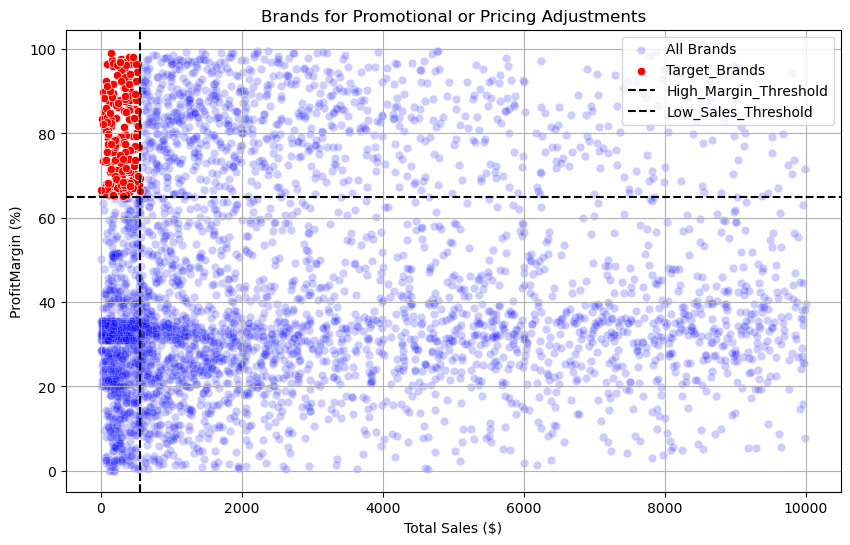

In [21]:
plt.figure(figsize =(10,6))
sb.scatterplot(data =brand_performance, x ='TotalSalesDollars', y ='ProfitMargin', color ="blue", label ="All Brands", alpha =0.2)
sb.scatterplot(data =target_brands, x ='TotalSalesDollars', y ='ProfitMargin', color ="red", label ="Target_Brands")

plt.axhline(high_margin_threshold, linestyle ='--', color ='black', label ="High_Margin_Threshold")
plt.axvline(low_sales_threshold, linestyle ='--', color ='black', label ="Low_Sales_Threshold")

plt.xlabel("Total Sales ($)")
plt.ylabel("ProfitMargin (%)")
plt.title("Brands for Promotional or Pricing Adjustments")
plt.legend()
plt.grid(True)
plt.show()


In [22]:
def format_dollars(value):
    if value >= 1_000_000:
        return f"{value / 1_000_000:.2f}M"
    elif value >= 1_000:
        return f"{value / 1_000:.2f}k"
    else:
        return str(value)

In [23]:
#2. Determine top vendors contributing to sales and gross profit.

top_vendors =df.groupby("vendorname")["TotalSalesDollars"].sum().nlargest(10)
top_brands =df.groupby("Description")["TotalSalesDollars"].sum().nlargest(10)

In [24]:
pd.set_option('display.float_format','{:,.0f}'.format)
top_vendors

vendorname
DIAGEO NORTH AMERICA INC     67,990,099
MARTIGNETTI COMPANIES        39,330,359
PERNOD RICARD USA            32,063,196
JIM BEAM BRANDS COMPANY      31,423,020
BACARDI USA INC              24,854,817
CONSTELLATION BRANDS INC     24,218,745
E & J GALLO WINERY           18,399,899
BROWN-FORMAN CORP            18,247,231
ULTRA BEVERAGE COMPANY LLP   16,502,544
M S WALKER INC               14,706,458
Name: TotalSalesDollars, dtype: float64

In [25]:
top_brands.apply(lambda x : format_dollars(x))

Description
Jack Daniels No 7 Black    7.96M
Tito's Handmade Vodka      7.40M
Grey Goose Vodka           7.21M
Capt Morgan Spiced Rum     6.36M
Absolut 80 Proof           6.24M
Jameson Irish Whiskey      5.72M
Ketel One Vodka            5.07M
Baileys Irish Cream        4.15M
Kahlua                     3.60M
Tanqueray                  3.46M
Name: TotalSalesDollars, dtype: object

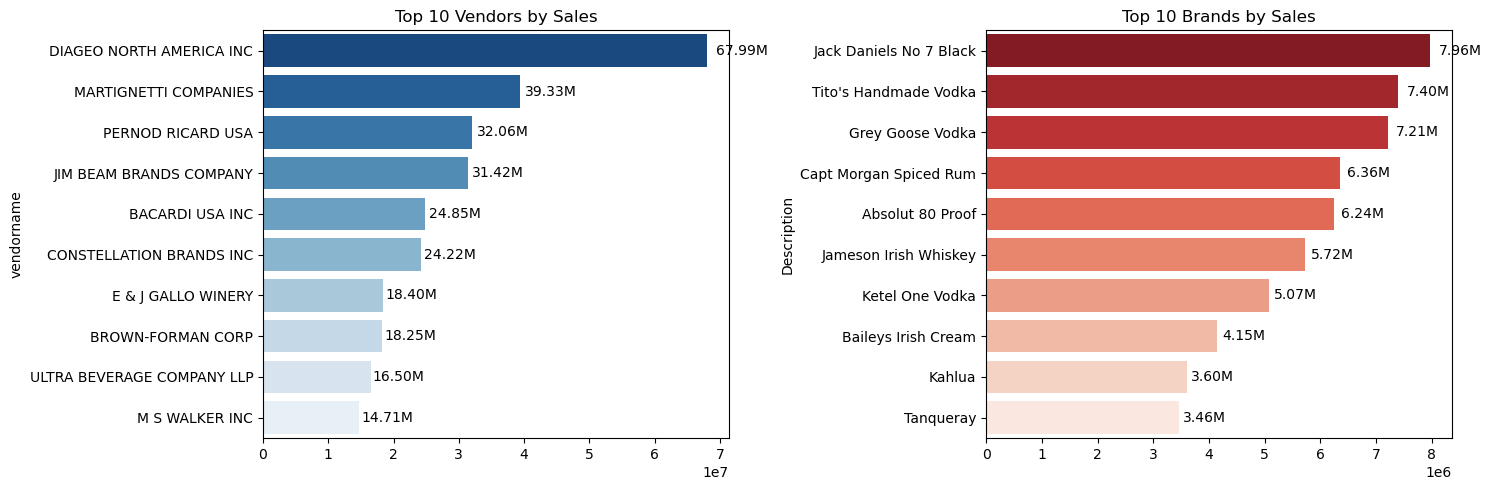

In [26]:
plt.figure(figsize=(15, 5))

# Plot for Top Vendors
plt.subplot(1, 2, 1)
ax1 = sb.barplot(y=top_vendors.index, x=top_vendors.values, palette="Blues_r")
plt.title("Top 10 Vendors by Sales")

for bar in ax1.patches:
    ax1.text(bar.get_width() + (bar.get_width() * 0.02),
             bar.get_y() + bar.get_height() / 2,
             format_dollars(bar.get_width()),
             ha='left', va='center', fontsize=10, color='black')

# Plot for Top Brands
plt.subplot(1, 2, 2)
ax2 = sb.barplot(y=top_brands.index.astype(str), x=top_brands.values, palette="Reds_r")
plt.title("Top 10 Brands by Sales")

for bar in ax2.patches:
    ax2.text(bar.get_width() + (bar.get_width() * 0.02),
             bar.get_y() + bar.get_height() / 2,
             format_dollars(bar.get_width()),
             ha='left', va='center', fontsize=10, color='black')

plt.tight_layout()
plt.show()

In [27]:
#3. Which vendors contribute the most to total purchase dollars?

vendor_performance =df.groupby('vendorname').agg({
    'TotalPurchaseDollar':'sum',
    'GrossProfit':'sum',
    'TotalSalesDollars':'sum'}).reset_index()


In [28]:
vendor_performance['PurchaseContribution%'] = vendor_performance['TotalPurchaseDollar'] * 100.00 / vendor_performance['TotalPurchaseDollar'].sum()

In [29]:
vendor_performance = round(vendor_performance.sort_values('PurchaseContribution%', ascending = False),2)

In [30]:
# Display top 10 vendors

top_vendors = vendor_performance.head(10)
top_vendors['TotalSalesDollars'] = top_vendors['TotalSalesDollars'].apply(format_dollars)
top_vendors['TotalPurchaseDollar'] = top_vendors['TotalPurchaseDollar'].apply(format_dollars)
top_vendors['GrossProfit'] = top_vendors['GrossProfit'].apply(format_dollars)


In [31]:
# top_vendors['PurchaseContribution%'] = top_vendors['PurchaseContribution%'].map(lambda x : f"{x:.2f}")

In [32]:
top_vendors

,vendorname,TotalPurchaseDollar,GrossProfit,TotalSalesDollars,PurchaseContribution%
25,DIAGEO NORTH AMERICA INC,50.10M,17.89M,67.99M,16
57,MARTIGNETTI COMPANIES,25.50M,13.83M,39.33M,8
68,PERNOD RICARD USA,23.85M,8.21M,32.06M,8
46,JIM BEAM BRANDS COMPANY,23.49M,7.93M,31.42M,8
6,BACARDI USA INC,17.43M,7.42M,24.85M,6
20,CONSTELLATION BRANDS INC,15.27M,8.95M,24.22M,5
11,BROWN-FORMAN CORP,13.24M,5.01M,18.25M,4
30,E & J GALLO WINERY,12.07M,6.33M,18.40M,4
106,ULTRA BEVERAGE COMPANY LLP,11.17M,5.34M,16.50M,4
53,M S WALKER INC,9.76M,4.94M,14.71M,3


In [33]:
top_vendors['PurchaseContribution%'] = pd.to_numeric(top_vendors['PurchaseContribution%'],errors='coerce')

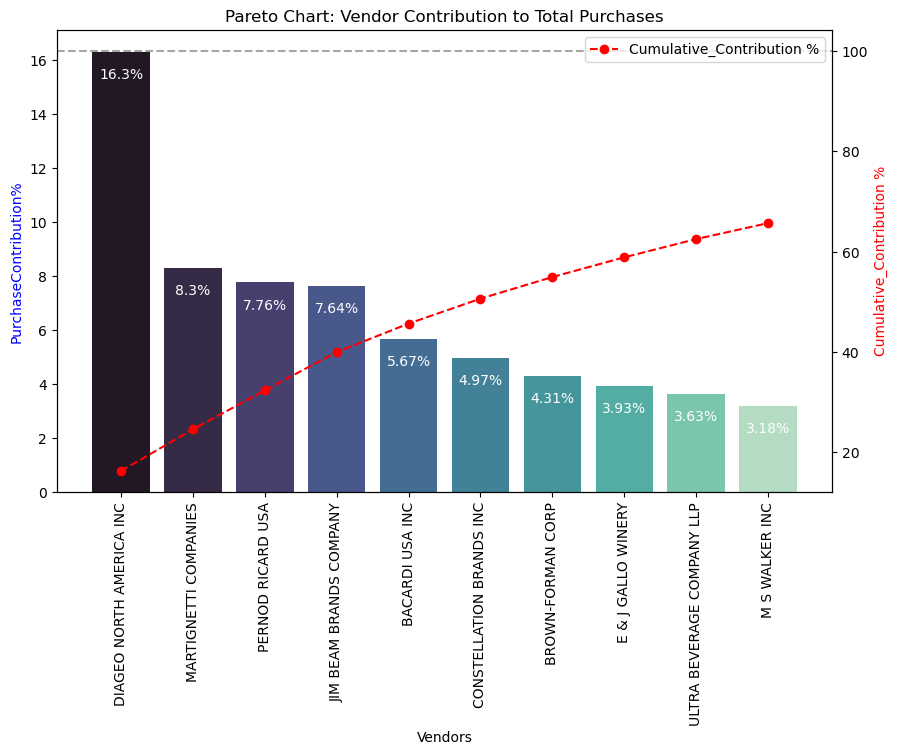

In [34]:
top_vendors['Cumulative_Contribution%'] = top_vendors['PurchaseContribution%'].cumsum()

fig, ax1 = plt.subplots(figsize=(10, 6))

# Bar plot for Purchase Contribution%
sb.barplot(
    x=top_vendors['vendorname'],
    y=top_vendors['PurchaseContribution%'],
    palette="mako",
    ax=ax1
)

for i, value in enumerate(top_vendors['PurchaseContribution%']):
    ax1.text(
        i, value - 1, str(value) + '%',
        ha='center',
        fontsize=10,
        color='white'
    )

# Line Plot for Cumulative Contribution%
ax2 = ax1.twinx()

ax2.plot(
    top_vendors['vendorname'],
    top_vendors['Cumulative_Contribution%'],
    color='red',
    marker='o',
    linestyle='dashed',
    label='Cumulative_Contribution %'
)

# Labels
ax1.set_xticklabels(
    top_vendors['vendorname'],
    rotation=90
)

ax1.set_ylabel('PurchaseContribution%', color='blue')
ax2.set_ylabel('Cumulative_Contribution %', color='red')
ax1.set_xlabel('Vendors')

# Title
ax1.set_title(
    'Pareto Chart: Vendor Contribution to Total Purchases'
)

# 100% reference line
ax2.axhline(
    y=100,
    color='gray',
    linestyle='dashed',
    alpha=0.7
)

# Legend
ax2.legend(loc='upper right')

plt.show()


In [35]:
#4. How much of total procurement is dependent on the top vendors?

print(f"Total Purchase Contribution of top 10 vendors is {round(top_vendors['PurchaseContribution%'].sum(),2)}%")

Total Purchase Contribution of top 10 vendors is 65.69%


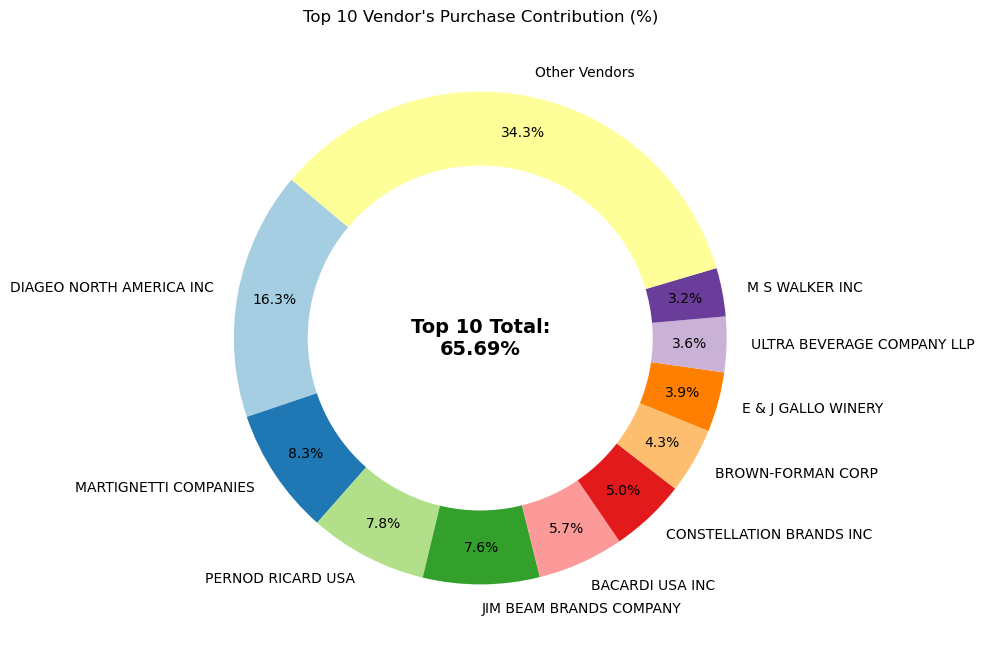

In [36]:
vendors = list(top_vendors['vendorname'].values)
purchase_contributions = list(top_vendors['PurchaseContribution%'].values)
total_contribution = sum(purchase_contributions)
remaining_contribution = 100 - total_contribution

# Append "Other Vendors" category
vendors.append("Other Vendors")
purchase_contributions.append(remaining_contribution)

# Donut Chart
fig, ax = plt.subplots(figsize=(8, 8))
wedges, texts, autotexts = ax.pie(
    purchase_contributions,
    labels=vendors,
    autopct='%1.1f%%',
    startangle=140,
    pctdistance=0.85,
    colors=plt.cm.Paired.colors
)

# Draw a white circle in the center to create a "donut" effect
centre_circle = plt.Circle((0, 0), 0.70, fc='white')
fig.gca().add_artist(centre_circle)

# Add Total Contribution annotation in the center
plt.text(
    0, 0,
    f"Top 10 Total:\n{total_contribution:.2f}%",
    fontsize=14,
    fontweight='bold',
    ha='center',
    va='center'
)

plt.title("Top 10 Vendor's Purchase Contribution (%)")
plt.show()

In [37]:
#5. Analyze the impact of bulk purchasing on unit costs.

df['UnitPurchasePrice'] = df['TotalPurchaseDollar'] / df['TotalPurchaseQuantity']

In [38]:
df["OrderSize"] = pd.qcut(df["TotalPurchaseQuantity"], q=3,labels = ["Small","Medium","Large"])

In [39]:
pd.options.display.float_format = '{:.4f}'.format


In [40]:
df.groupby('OrderSize')[['UnitPurchasePrice']].mean()

,UnitPurchasePrice
OrderSize,
Small,39.0575
Medium,15.4864
Large,10.7776


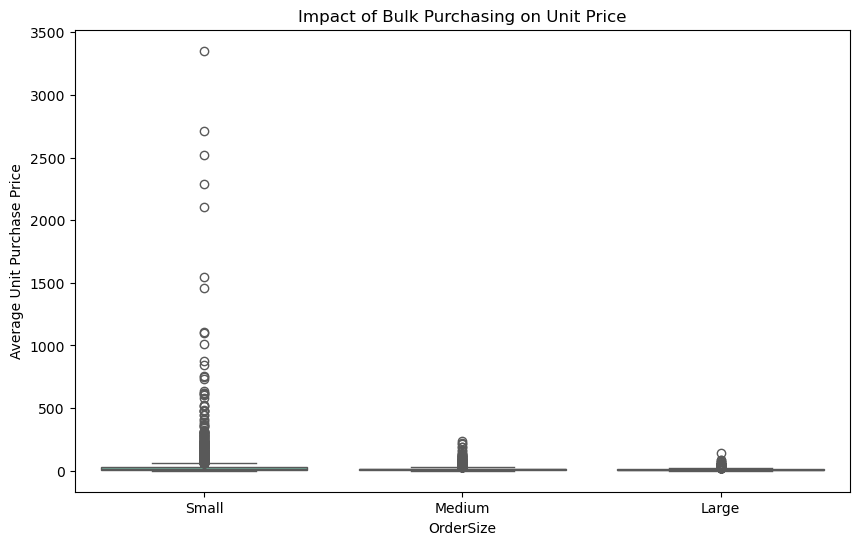

In [41]:
plt.figure(figsize = (10,6))
sb.boxplot(data = df, x = "OrderSize", y = "UnitPurchasePrice", palette = "Set2")
plt.title("Impact of Bulk Purchasing on Unit Price")
plt.xlabel("OrderSize")
plt.ylabel("Average Unit Purchase Price")
plt.show()

• Vendors buying in bulk (Large Order Size) get the lowest unit price ($10.78 per unit), meaning higher margins if they can manage inventory efficiently.
• The price difference between Small and Large orders is substantial (~72% reduction in unit cost).
• This suggests that bulk pricing strategies successfully encourage vendors to purchase in larger volumes, leading to higher overall sales despite lower per-unit revenue.


In [42]:
#5. Assess inventory turnover to reduce holding costs and improve efficiency.
#   Which vendors have low inventory turnover, indicating excess stock and slow-moving products?

df[df['StockTurnover'] < 1].groupby('vendorname')[['StockTurnover']].mean().sort_values('StockTurnover',ascending = True).head(10)
    

,StockTurnover
vendorname,
ALISA CARR BEVERAGES,0.6154
HIGHLAND WINE MERCHANTS LLC,0.7083
PARK STREET IMPORTS LLC,0.7513
Circa Wines,0.7557
Dunn Wine Brokers,0.7660
CENTEUR IMPORTS LLC,0.7740
SMOKY QUARTZ DISTILLERY LLC,0.7838
TAMWORTH DISTILLING,0.7971
THE IMPORTED GRAPE LLC,0.8076


In [43]:
#6. How much capital is locked in unsold inventory per vendor, and which vendors contribute the most to it?

df["UnsoldInventoryValue"] = (df["TotalPurchaseQuantity"] - df["TotalSalesQuantity"]) * df["purchaseprice"]
print('Total Unsold Capital:',format_dollars(df["UnsoldInventoryValue"].sum()))

Total Unsold Capital: 2.71M


In [44]:
# Aggregate capital locked per vendor

Inventory_value_per_vendor = df.groupby("vendorname")["UnsoldInventoryValue"].sum().reset_index()

In [45]:
# Sort vendors with the highest locked capital

Inventory_value_per_vendor = Inventory_value_per_vendor.sort_values(by = "UnsoldInventoryValue",ascending = False)
Inventory_value_per_vendor ["UnsoldInventoryValue"] = Inventory_value_per_vendor["UnsoldInventoryValue"].apply(format_dollars)
Inventory_value_per_vendor.head(10)

,vendorname,UnsoldInventoryValue
25,DIAGEO NORTH AMERICA INC,722.21k
46,JIM BEAM BRANDS COMPANY,554.67k
68,PERNOD RICARD USA,470.63k
116,WILLIAM GRANT & SONS INC,401.96k
30,E & J GALLO WINERY,228.28k
79,SAZERAC CO INC,198.44k
11,BROWN-FORMAN CORP,177.73k
20,CONSTELLATION BRANDS INC,133.62k
61,MOET HENNESSY USA INC,126.48k
77,REMY COINTREAU USA INC,118.60k


What is the profit margins of top-performing and low-performing vendors?

In [46]:
top_threshold = df["TotalSalesDollars"].quantile(0.75)
low_threshold = df["TotalSalesDollars"].quantile(0.25)

In [47]:
top_vendors = df[df["TotalSalesDollars"] >= top_threshold]["ProfitMargin"].dropna()
low_vendors = df[df["TotalSalesDollars"] <= low_threshold]["ProfitMargin"].dropna()


In [48]:
top_vendors.mean()

np.float64(31.172242371573912)

In [49]:
low_vendors.mean()

np.float64(41.54976311611542)

In [50]:
Avg_top_vendors_profit_margin = top_vendors.mean()
print("Average Profit Margin of Top Vendors:",Avg_top_vendors_profit_margin)

Average Profit Margin of Top Vendors: 31.172242371573912


In [51]:
Avg_low_vendors_profit_margin = low_vendors.mean()
print("Average Profit Margin of low Vendors:",Avg_low_vendors_profit_margin)

Average Profit Margin of low Vendors: 41.54976311611542
